# **Day 50: Object Oriented Programming (Part 10) - Abstraction**

We are halfway through the 100 days!

**Abstraction** means showing **only the important things** and hiding the complex details.

**Real-life example:** To drive a car, we only need the steering, accelerator and brake. We do not need to know how the engine works inside.

In Python, we use **abstract classes** for this. An abstract class is like a **rule book** or a **contract**:
- It **cannot be used directly** to make objects.
- It says: "Every child class **must** have these methods."

We make abstract classes using the `abc` module (**A**bstract **B**ase **C**lasses).

In [1]:
from abc import ABC, abstractmethod

class Shape(ABC):
    @abstractmethod
    def area(self):
        pass

    @abstractmethod
    def perimeter(self):
        pass

    def describe(self):              # A normal method is also allowed
        return f"{type(self).__name__}: area = {self.area():.2f}, perimeter = {self.perimeter():.2f}"

# Shape()          # This will raise a TypeError (cannot create an object of an abstract class)

In [2]:
class Square(Shape):
    def __init__(self, side):
        self.side = side
    def area(self):
        return self.side ** 2
    # We forgot to write perimeter()

# Square(4)        # This will raise a TypeError (perimeter is missing)

In [3]:
import math

class Square(Shape):
    def __init__(self, side):
        self.side = side
    def area(self):
        return self.side ** 2
    def perimeter(self):
        return 4 * self.side

class Circle(Shape):
    def __init__(self, r):
        self.r = r
    def area(self):
        return math.pi * self.r ** 2
    def perimeter(self):
        return 2 * math.pi * self.r

for s in [Square(4), Circle(2.5)]:
    print(s.describe())

Square: area = 16.00, perimeter = 16.00
Circle: area = 19.63, perimeter = 15.71


**Why is this useful?** Python stops us **immediately** if we forget to write a required method, instead of giving an error much later when that method is finally used.

## **Example from Remote Sensing: A Sensor Rule Book**
Every satellite sensor must be able to:
1. Tell its band names for Red and NIR.
2. Convert raw pixel numbers (called **DN, Digital Numbers**) into **reflectance** (the real fraction of light reflected, from 0 to 1).

Different satellites do step 2 in different ways, using their own numbers. An abstract class makes sure every sensor class follows the same rules.

(The conversion numbers below are simplified examples.)

In [4]:
class Sensor(ABC):
    def __init__(self, name, resolution_m):
        self.name = name
        self.resolution_m = resolution_m

    @abstractmethod
    def to_reflectance(self, dn):
        """Convert a raw digital number into reflectance (0 to 1)."""

    @abstractmethod
    def band_for(self, colour):
        """Return the band name for 'red' or 'nir'."""

    def ndvi(self, red_dn, nir_dn):            # Written once, used by all sensors
        red = self.to_reflectance(red_dn)
        nir = self.to_reflectance(nir_dn)
        return (nir - red) / (nir + red)

class Landsat8(Sensor):
    def __init__(self):
        super().__init__("Landsat 8", 30)
    def to_reflectance(self, dn):
        return dn * 0.0000275 - 0.2            # Collection 2 style scaling
    def band_for(self, colour):
        return {"red": "B4", "nir": "B5"}[colour]

class Sentinel2(Sensor):
    def __init__(self):
        super().__init__("Sentinel-2", 10)
    def to_reflectance(self, dn):
        return dn / 10000                     # Sentinel-2 values are reflectance x 10000
    def band_for(self, colour):
        return {"red": "B4", "nir": "B8"}[colour]

readings = [(Landsat8(), 8500, 21000), (Sentinel2(), 600, 3800)]
for sensor, red_dn, nir_dn in readings:
    print(f"{sensor.name:<11} Red={sensor.band_for('red')} NIR={sensor.band_for('nir')}  "
          f"NDVI = {sensor.ndvi(red_dn, nir_dn):.3f}")

Landsat 8   Red=B4 NIR=B5  NDVI = 0.836
Sentinel-2  Red=B4 NIR=B8  NDVI = 0.727


Let us understand the code above:
- `Sensor` is the **abstract class** (the rule book). It cannot be used directly.
- Both `Landsat8` and `Sentinel2` **must** write `to_reflectance()` and `band_for()`.
- The `ndvi()` method is written **only once** in `Sensor`, but it works for every sensor because it uses the child's own `to_reflectance()`.

## **Class Diagram**

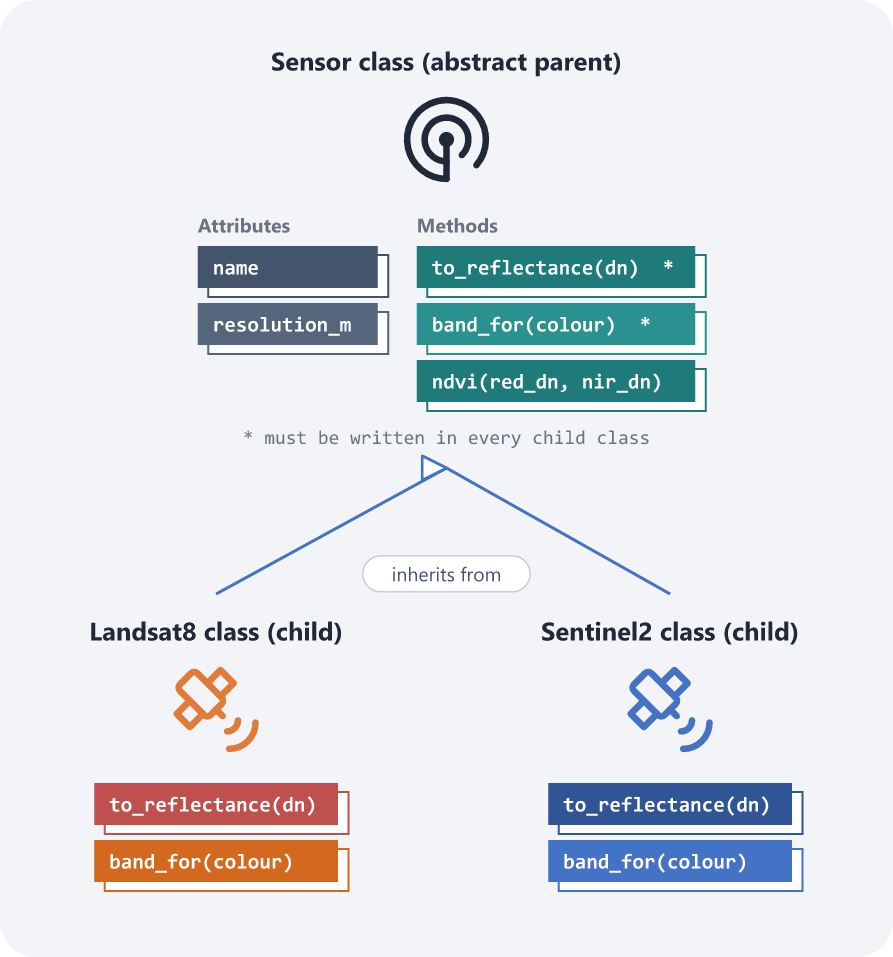

## **The Four Pillars of OOP**
We have now learned all four main ideas of OOP:

| Pillar | Simple meaning | Day |
|---|---|---|
| **Encapsulation** | Protect the data inside the object | 44 |
| **Inheritance** | A child class gets features from a parent class | 45, 46 |
| **Polymorphism** | Same method name, different behaviour | 47 |
| **Abstraction** | Show only what is needed, set rules for child classes | 50 |

In [5]:
# Quick question
# Can we create an object of this class? Why or why not?
# from abc import ABC, abstractmethod
# class Animal(ABC):
#     @abstractmethod
#     def sound(self): ...
# a = Animal()